# Setup

In [1]:
# Base imports
import os
import pickle

# Compute imports
import numpy as np
import pandas as pd
import scipy
from tqdm.notebook import tqdm, trange

# Plotting imports
import matplotlib
matplotlib.rcParams['pdf.fonttype'] = 42
from matplotlib import pyplot as plt
import seaborn as sns
from plotly import express as px

# ML import
#from sklearn.decomposition import NMF
#from sklearn.metrics import mean_squared_error, mntn_absolute_error

In [2]:
df_genes = pd.read_pickle('/mnt/craig/pan_phylon/S_pyogenes/processed/cd-hit-results/sim80/Spyo_strain_by_gene.pickle.gz')
df_genes.fillna(0, inplace=True)
df_genes = df_genes.sparse.to_dense().astype('int8')

display(
    df_genes.shape,
    df_genes.head()
)

(8761, 402)

,1010840.4,1048264.3,1150773.3,1150773.4,1235829.3,1314.1001,1314.1002,1314.1003,1314.1004,1314.1005,...,GCF_055362005.1,GCF_055362025.1,GCF_055362045.1,GCF_055362065.1,GCF_055362085.1,GCF_055378755.1,GCF_900608505.1,GCF_900636425.1,GCF_900636485.1,GCF_900636725.1
Spyo_C0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Spyo_C1000,0,0,0,0,0,1,0,1,0,0,...,1,0,0,1,0,0,1,0,1,0
Spyo_C1001,0,0,0,0,0,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Spyo_C1002,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Spyo_C1003,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [3]:
df_genes.sum()

1010840.4          1662
1048264.3          1766
1150773.3          1716
1150773.4          1715
1235829.3          1750
                   ... 
GCF_055378755.1    1732
GCF_900608505.1    1790
GCF_900636425.1    1698
GCF_900636485.1    1810
GCF_900636725.1    1719
Length: 402, dtype: int64

In [4]:
metadata = pd.read_csv('/mnt/craig/pan_phylon/S_pyogenes/metadata/enriched_metadata.csv', index_col=0, dtype='object')

display(
    metadata.shape,
    metadata.head()
)

(402, 136)

,genome_id,source,genome_name,organism_name,taxon_id,strain,# ambiguous bases,# genomes,0,1,...,mash_cluster_initial,mash_cluster_filtered,iso_raw,host_cat,source_cat,country_merged,Num of emm-clusters,Predicted emm-type,Possible emm-like alleles,emm cluster
0,1010840.4,BV-BRC,Streptococcus pyogenes MGAS1882,Streptococcus pyogenes MGAS1882,1010840,MGAS1882,NaN,NaN,NaN,NaN,...,89,NaN,NaN,Not Specified,Not Specified,USA,2,emm_59.0,_emm_174.1*,E6
1,1048264.3,BV-BRC,Streptococcus pyogenes HKU QMH11M0907901,NaN,1048264,HKU QMH11M0907901,NaN,NaN,NaN,NaN,...,6,NaN,blood from scarlet fever outbreak,Human,Blood,China,1,emm_12.0,NaN,A-C4
2,1150773.3,BV-BRC,Streptococcus pyogenes JRS4,NaN,1150773,JRS4,NaN,NaN,NaN,NaN,...,7,8.0,NaN,Not Specified,Not Specified,NaN,1,emm_6.52,NaN,Single protein cluster clade Y
3,1150773.4,BV-BRC,Streptococcus pyogenes JRS4,NaN,1150773,JRS4,NaN,NaN,NaN,NaN,...,7,8.0,NaN,Not Specified,Not Specified,NaN,1,emm_6.52,NaN,Single protein cluster clade Y
4,1235829.3,BV-BRC,Streptococcus pyogenes A20,Streptococcus pyogenes A20,1235829,A20,NaN,NaN,NaN,NaN,...,2,2.0,necrotizing fasciitis patient,Human,Soft Tissue,Taiwan,1,emm_1.0,NaN,A-C3


## useful functions

In [5]:
# # Function for seperating Core-, Accessory-, & Rare- genomes

# def find_pangenome_segments(df_genes, threshold=0.1, ax=None):
#     '''
#     Computes the gene frequency thresholds at which a gene can be categorized as 
#     core, accessory, or unique. Specifically, models the gene frequency distribution
#     as the sum of two power laws (one flipped), and fits the CDF to a five-parameter
#     function dervied from those power laws. Also identifies the inflection point and
#     the core and unique extremes relative to the inflection point and threshold.
    
#           PMF(x;c1,c2,a1,a2) ~ c1 * x^-a1 + c2 * (n-x)^-a2
#         CDF(x;c1,c2,a1,a2,k) ~ c1/(1-a1) * x^(1-a1) - c2/(1-a2) * (n-x)^(1-a2) + k
        
#     Where x = frequency, n = maximum frequency + 1, other variables are parameters.
    
#     Pangenome segments example at 10%:
#     - N = total strains, R = computed inflection point
#     - Core: Observed in >= R + (1 - 0.1) * (N-R) strains
#     - Unique: Observed in <= 0.1 * R strains
#     - Accessory: Everything in between
    
#     Parameters
#     ----------
#     df_genes : pd.DataFrame
#         Binary gene x strain table.
#     threshold : float
#         Proximity to each frequency extreme compared to inflection point
#         that determines if a gene is core, unique, or accessory (default 0.1)
#     ax : plt.axes
#         If provided, plots pangenome frequency CDF with segments (default None)
        
#     Returns
#     -------
#     segments : tuple
#         2-tuple with (min core limit, max unique limit), not rounded.
#     popt : tuple
#         5-tuple with fitted CDF parameters (c1,c2,a1,a2,k). Note that
#         c1, c2, and k are scaled relative to the number of unique genes
#     r_squared : float
#         R^2 between fit and observed cumulative gene frequency distribution
#     ax : plt.axes
#         If ax is not None, returns axis with plots
#     '''

#     ''' Computing gene frequencies and frequency counts '''
#     if type(df_genes) == pd.DataFrame: # data frame provided
#         df_gene_freq = df_genes.fillna(0).sum(axis=1)
#     else: # array provided
#         df_gene_freq = pd.Series(data=df_genes.sum(axis=1), index=map(lambda x: 'G' + str(x), range(df_genes.shape[0])))
#     df_freq_counts = df_gene_freq.value_counts()
#     if 0 in df_freq_counts.index: # filter out unobserved genes (i.e. when subsetting genomes)
#         df_freq_counts.drop(index=0, inplace=True)
#     df_freq_counts = df_freq_counts[sorted(df_freq_counts.index)]
#     cumulative_frequencies = np.cumsum(df_freq_counts.values)
#     frequency_bins = np.array(df_freq_counts.index)
    
#     ''' Fitting CDF '''
#     X = frequency_bins.astype(float)
#     Y = cumulative_frequencies.astype(float)
#     n = max(frequency_bins) + 1
#     dual_power_cdf = lambda x,c1,c2,a1,a2,k: \
#         Y[0]*(c1*np.power(x,1.0-a1)/(1.0-a1) - c2*np.power(n-x,1.0-a2)/(1.0-a2) + k)
#     p0 = [1.0,1.0,2.0,2.0,1.0]
#     bounds = ([0.0,0.0,1.0,1.0,0.0],[np.inf,np.inf,np.inf,np.inf,Y[-1]/Y[0]])
#     popt, pcov = scipy.optimize.curve_fit(dual_power_cdf, X, Y, p0=p0, bounds=bounds, maxfev=100000)
    
#     ''' Extracting inflection point of CDF and frequency thresholds '''
#     dual_power_pdf = lambda x,c1,c2,a1,a2: Y[0]*(c1*np.power(x,-a1) + c2*np.power(n-x,-a2))
#     dual_power_pdf_fit = lambda x: dual_power_pdf(x,*popt[:4]) # minimize PMF
#     res = scipy.optimize.minimize_scalar(dual_power_pdf_fit, method='bounded', bounds=[1,n-1])
#     inflection_freq = res.x # inflection point x, i.e. frequency threshold 
#     unique_strains_max = inflection_freq * threshold
#     core_strains_min = inflection_freq + (n - 1 - inflection_freq) * (1.0 - threshold)
#     segments = (core_strains_min, unique_strains_max)
    
#     ''' Curve fit evaluation: R^2 and MAE
#         R^2 technically invalid for nonlinear fits but commonly reported
#         MAE is more relevant for judging nonlinear models '''
#     Yfit = np.array(list(map(lambda x: dual_power_cdf(x,*popt), X))) # fitted CDF
#     SStot = np.sum(np.square(Y - Y.mean()))
#     SSres = np.sum(np.square(Y - Yfit))
#     r_squared = 1 - (SSres/SStot)
#     # rmse = np.sqrt(np.square(Y - Yfit).mean())
#     mae = np.abs(Y - Yfit).mean()
    
#     ''' Optionally, generating plot '''
#     if ax:
#         ax.plot(X, Y, label='observed')
#         ax.plot(X, Yfit, label='fit', ls='--')
#         ax.scatter([inflection_freq], [dual_power_cdf(inflection_freq,*popt)], 
#                    label='inflection point', color='black', alpha=0.7)
#         ax.axvline(unique_strains_max, ls='--', color='k')
#         ax.axvline(core_strains_min, ls='--', color='k')
#         ax.axvline(inflection_freq, ls='--', color='lightgray')
        
#         unique_rounded = int(unique_strains_max) + 1
#         core_rounded = int(core_strains_min)
#         unique_text = 'Unique:\n<' + str(unique_rounded)
#         core_text = 'Core:\n>' + str(core_rounded)
#         r2_text = 'R^2=' + str(np.round(r_squared,3))
#         mae_text = 'MAE=' + str(np.round(mae,2))
#         ax.text(unique_strains_max + n*0.02, Y[0], unique_text, ha='left', va='bottom')
#         ax.text(core_strains_min - n*0.02, Y[0], core_text, ha='right', va='bottom')
#         ax.text(unique_strains_max + n*0.1, 0.95*Y[-1], r2_text, ha='left', va='bottom')
#         ax.text(unique_strains_max + n*0.1, 0.95*Y[-1], mae_text, ha='left', va='top')
#         ax.set_xlabel('Gene frequency')
#         ax.set_ylabel('Cumulative genes')
#         return segments, popt, r_squared, mae, ax
#     else:
#         return segments, popt, r_squared, mae

In [6]:
import scipy.optimize

def find_pangenome_segments(df_genes, threshold=0.1, custom_core_threshold=None, custom_rare_threshold=None, ax=None):
    '''
    Computes the gene frequency thresholds at which a gene can be categorized as 
    core, accessory, or rare. Specifically, models the gene frequency distribution
    as the sum of two power laws (one flipped), and fits the CDF to a five-parameter
    function derived from those power laws. Also identifies the inflection point and
    the core and rare extremes relative to the inflection point and threshold.
    
          PMF(x;c1,c2,a1,a2) ~ c1 * x^-a1 + c2 * (n-x)^-a2
        CDF(x;c1,c2,a1,a2,k) ~ c1/(1-a1) * x^(1-a1) - c2/(1-a2) * (n-x)^(1-a2) + k
        
    Where x = frequency, n = maximum frequency + 1, other variables are parameters.
    
    Pangenome segments example at 10%:
    - N = total strains, R = computed inflection point
    - Core: Observed in >= R + (1 - 0.1) * (N-R) strains
    - Rare: Observed in <= 0.1 * R strains
    - Accessory: Everything in between
    
    Parameters
    ----------
    df_genes : pd.DataFrame
        Binary gene x strain table.
    threshold : float
        Proximity to each frequency extreme compared to inflection point
        that determines if a gene is core, rare, or accessory (default 0.1)
    custom_core_threshold : float, optional
        Custom threshold for core genes as a percentage (0 to 1). If provided,
        overrides the default core threshold (e.g., 0.9671 for 96.71%).
    custom_rare_threshold : float, optional
        Custom threshold for rare genes as a percentage (0 to 1). If provided,
        overrides the default rare threshold (e.g., 0.05 for 5%).
    ax : plt.axes
        If provided, plots pangenome frequency CDF with segments (default None)
        
    Returns
    -------
    segments : tuple
        2-tuple with (min core limit, max rare limit), not rounded.
    popt : tuple
        5-tuple with fitted CDF parameters (c1,c2,a1,a2,k). Note that
        c1, c2, and k are scaled relative to the number of rare genes
    r_squared : float
        R^2 between fit and observed cumulative gene frequency distribution
    mae : float
        Mean absolute error between fit and observed cumulative gene frequency distribution
    ax : plt.axes
        If ax is not None, returns axis with plots
    '''

    ''' Computing gene frequencies and frequency counts '''
    if type(df_genes) == pd.DataFrame: # data frame provided
        df_gene_freq = df_genes.fillna(0).sum(axis=1)
    else: # array provided
        df_gene_freq = pd.Series(data=df_genes.sum(axis=1), index=map(lambda x: 'G' + str(x), range(df_genes.shape[0])))
    df_freq_counts = df_gene_freq.value_counts()
    if 0 in df_freq_counts.index: # filter out unobserved genes (i.e. when subsetting genomes)
        df_freq_counts.drop(index=0, inplace=True)
    df_freq_counts = df_freq_counts[sorted(df_freq_counts.index)]
    cumulative_frequencies = np.cumsum(df_freq_counts.values)
    frequency_bins = np.array(df_freq_counts.index)
    
    ''' Fitting CDF '''
    X = frequency_bins.astype(float)
    Y = cumulative_frequencies.astype(float)
    n = max(frequency_bins) + 1
    N = max(frequency_bins)  # Total number of strains
    dual_power_cdf = lambda x,c1,c2,a1,a2,k: \
        Y[0]*(c1*np.power(x,1.0-a1)/(1.0-a1) - c2*np.power(n-x,1.0-a2)/(1.0-a2) + k)
    p0 = [1.0,1.0,2.0,2.0,1.0]
    bounds = ([0.0,0.0,1.0,1.0,0.0],[np.inf,np.inf,np.inf,np.inf,Y[-1]/Y[0]])
    popt, pcov = scipy.optimize.curve_fit(dual_power_cdf, X, Y, p0=p0, bounds=bounds, maxfev=100000)
    
    ''' Extracting inflection point of CDF and frequency thresholds '''
    dual_power_pdf = lambda x,c1,c2,a1,a2: Y[0]*(c1*np.power(x,-a1) + c2*np.power(n-x,-a2))
    dual_power_pdf_fit = lambda x: dual_power_pdf(x,*popt[:4]) # minimize PMF
    res = scipy.optimize.minimize_scalar(dual_power_pdf_fit, method='bounded', bounds=[1,n-1])
    inflection_freq = res.x # inflection point x, i.e. frequency threshold 
    
    # Set thresholds based on custom values or default calculations
    if custom_rare_threshold is not None:
        rare_strains_max = custom_rare_threshold * N
    else:
        rare_strains_max = inflection_freq * threshold
    if custom_core_threshold is not None:
        core_strains_min = custom_core_threshold * N
    else:
        core_strains_min = inflection_freq + (n - 1 - inflection_freq) * (1.0 - threshold)
    segments = (core_strains_min, rare_strains_max)
    
    ''' Curve fit evaluation: R^2 and MAE
        R^2 technically invalid for nonlinear fits but commonly reported
        MAE is more relevant for judging nonlinear models '''
    Yfit = np.array(list(map(lambda x: dual_power_cdf(x,*popt), X))) # fitted CDF
    SStot = np.sum(np.square(Y - Y.mean()))
    SSres = np.sum(np.square(Y - Yfit))
    r_squared = 1 - (SSres/SStot)
    mae = np.abs(Y - Yfit).mean()
    
    ''' Optionally, generating plot '''
    if ax:
        ax.plot(X, Y, label='observed')
        ax.plot(X, Yfit, label='fit', ls='--')
        ax.scatter([inflection_freq], [dual_power_cdf(inflection_freq,*popt)], 
                   label='inflection point', color='black', alpha=0.7)
        ax.axvline(rare_strains_max, ls='--', color='k')
        ax.axvline(core_strains_min, ls='--', color='k')
        ax.axvline(inflection_freq, ls='--', color='lightgray')
        
        rare_rounded = int(rare_strains_max) + 1
        core_rounded = int(core_strains_min)
        rare_text = 'Rare:\n<' + str(rare_rounded)
        core_text = 'Core:\n>' + str(core_rounded)
        r2_text = 'R^2=' + str(np.round(r_squared,3))
        mae_text = 'MAE=' + str(np.round(mae,2))
        ax.text(rare_strains_max + n*0.02, Y[0], rare_text, ha='left', va='bottom')
        ax.text(core_strains_min - n*0.02, Y[0], core_text, ha='right', va='bottom')
        ax.text(rare_strains_max + n*0.1, 0.95*Y[-1], r2_text, ha='left', va='bottom')
        ax.text(rare_strains_max + n*0.1, 0.95*Y[-1], mae_text, ha='left', va='top')
        ax.set_xlabel('Gene frequency')
        ax.set_ylabel('Cumulative genes')
        return segments, popt, r_squared, mae, ax
    else:
        return segments, popt, r_squared, mae

# MLST treemap

In [7]:
# Assuming metadata is your DataFrame
mlst_counts = metadata.mlst.value_counts()

# Option: Show top N MLST values and group the rest into 'Other'
top_n = 10  # Adjust this value as needed

# Get the top N MLST values
top_mlst = mlst_counts.nlargest(top_n)

# Calculate the sum of the remaining MLST counts for 'Other'
other_count = mlst_counts.sum() - top_mlst.sum()

# Create a Series for 'Other'
other_series = pd.Series([other_count], index=['Other'])

# Concatenate the top N and 'Other'
mlst_for_treemap = pd.concat([top_mlst, other_series])

# Create the treemap using Plotly Express with a pastel color scheme
fig = px.treemap(
    mlst_for_treemap.reset_index(),
    path=['index'],  # MLST values (or 'Other')
    values=0,        # Counts
    color_discrete_sequence=px.colors.qualitative.Set3  # Pastel-like color scheme
)

# Add a title and set the figure size
fig.update_layout(
    title="Treemap of MLST Values for S. pyogenes Dataset",
    width=800,      # Increased width for better visibility
    height=800       # Increased height for better visibility
)

# Display the treemap
fig.show()

In [8]:
fig.write_image("top10_mlst.pdf")

# CAR genomes

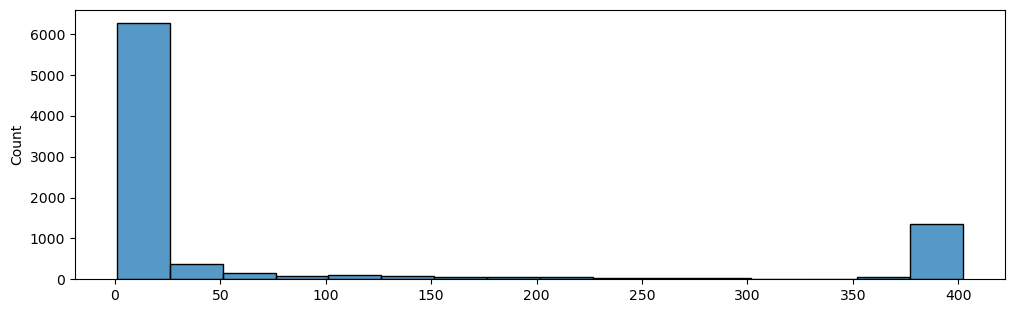

In [9]:
df_gene_freq = df_genes.sum(axis=1)

figsize = (12, 3.5)
fig, ax = plt.subplots(figsize=figsize)

sns.histplot(df_gene_freq, binwidth=25, ax=ax)
#plt.yscale('log')
plt.show()

In [10]:
# median value of counts in the middle
cond1 = df_gene_freq > 200
cond2 = df_gene_freq < 1300

df_gene_freq[cond1 & cond2].median()

np.float64(401.0)

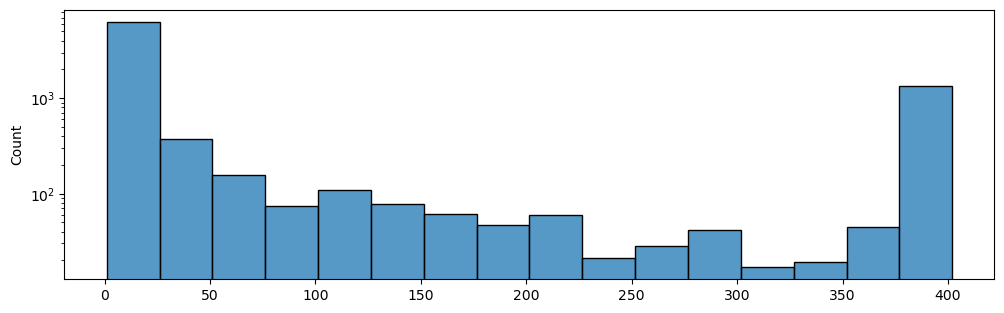

In [11]:
df_gene_freq = df_genes.sum(axis=1)

figsize = (12, 3.5)
fig, ax = plt.subplots(figsize=figsize)

sns.histplot(df_gene_freq, binwidth=25, ax=ax)
plt.yscale('log')
plt.show()

In [12]:
fig.savefig('freq_log.png', transparent=True)

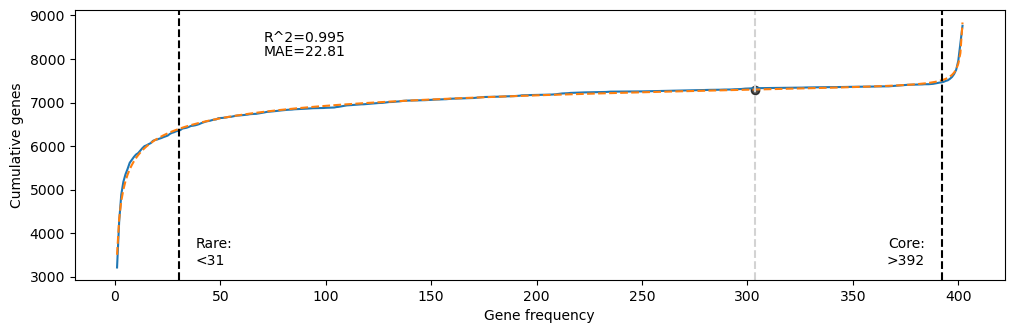

In [13]:
figsize = (12, 3.5)
fig, ax = plt.subplots(figsize=figsize)

segments, popt, r_squared, mae, ax = find_pangenome_segments(df_genes, threshold=0.1, ax=ax)

In [14]:
fig.savefig('cdf.pdf', transparent=True)

In [15]:
df_freq = df_genes.sum(axis=1)

df_core = df_genes[df_freq > np.floor(segments[0])]
df_rare = df_genes[df_freq < np.ceil(segments[1])]

acc_gene_list = list(set(df_genes.index)
                     - set(df_core.index)
                     - set(df_rare.index)
                    )

df_acc = df_genes.loc[acc_gene_list].copy()

display(
    df_core.shape,
    df_acc.shape,
    df_rare.shape
)

(1298, 402)

(1111, 402)

(6352, 402)

In [16]:
core_genome_threshold = segments[0] / df_genes.shape[1]
rare_genome_threshold = segments[1] / df_genes.shape[1]
print(f'core genome threshold: {100 * core_genome_threshold} %')
print(f'rare genome threshold: {100 * rare_genome_threshold} %')

core genome threshold: 97.55262364989106 %
rare genome threshold: 7.552623649891056 %


In [17]:
# Make a dataframe for plotting CAR genome distribution per strain
df_car_dist = pd.DataFrame(index=df_genes.columns, columns=['core', 'acc','rare'])

# Fill in CAR
df_car_dist['core'] = df_core.sum()
df_car_dist['acc'] = df_acc.sum()
df_car_dist['rare'] = df_rare.sum()
df_car_dist['sum'] = df_car_dist.sum(axis=1)

df_car_dist.sort_values(by='sum', ascending=True)

,core,acc,rare,sum
1314.1005,1296,230,26,1552
1314.196,1295,242,28,1565
GCF_055361825.1,1295,244,29,1568
1437008.3,1296,254,21,1571
GCF_055361865.1,1298,248,27,1573
...,...,...,...,...
1314.2589,1294,487,123,1904
GCF_041072725.1,1298,457,179,1934
GCF_041071735.1,1297,491,161,1949
GCA_000732385.1,1087,259,608,1954


In [18]:
import plotly.graph_objects as go

# Sort the DataFrame by 'rare'
df_sorted = df_car_dist.sort_values(by='sum')

# Create x as a sequence representing the ordered samples
x = list(range(len(df_sorted)))

# Create a new figure
fig = go.Figure()

# Add scatter traces with stackgroup for stacking areas
fig.add_trace(go.Scatter(
    x=x,
    y=df_sorted['core'],
    name='core',
    stackgroup='one',
    mode='lines',
    line=dict(color='#8300c4'),
    fillcolor='#bea2cc'
))
fig.add_trace(go.Scatter(
    x=x,
    y=df_sorted['acc'],
    name='acc',
    stackgroup='one',
    mode='lines',
    line=dict(color='#ff7400'),
    fillcolor='#ffcf86'
))
fig.add_trace(go.Scatter(
    x=x,
    y=df_sorted['rare'],
    name='rare',
    stackgroup='one',
    mode='lines',
    line=dict(color='#93c47d'),
    fillcolor='#7bd7c3'
))

# Update layout to match original specifications
fig.update_layout(
    title='Filled Area Plot of Core, Acc, and Rare',
    xaxis_title='Samples ordered by Rare',
    yaxis_title='Values',
    yaxis=dict(range=[0, 2500]), # changed to 1000
    autosize=False,
    width=1200,
    height=550,
    margin=dict(l=50, r=50, b=100, t=100, pad=4),
    paper_bgcolor='white',
    plot_bgcolor='#e5e6eb'
)

# Hide x-axis labels
fig.update_xaxes(visible=False)

# Show the plot
fig.show()

In [19]:
print(
    df_core.sum().median(),
    df_acc.sum().median(),
    df_rare.sum().median()
)

1297.0 411.0 52.0


In [20]:
print(
    df_core.sum().std(),
    df_acc.sum().std(),
    df_rare.sum().std()
)

29.28240883199556 71.33888394018888 59.95307694020037


In [21]:
sigma_mult = 4 # outlier multiplier

min_core_size = int(
    df_core.sum().median() - df_core.sum().std()*sigma_mult
)

min_acc_size = int(
    df_acc.sum().median() - df_acc.sum().std()*sigma_mult
)

max_rare_size = int(
    df_rare.sum().median() + df_rare.sum().std()*sigma_mult
)

max_pan_size = int(
    df_genes.sum().median() + df_genes.sum().std()*sigma_mult
)

cond1 = df_core.sum() < min_core_size
cond2 = df_acc.sum() < min_acc_size
cond3 = df_rare.sum() > max_rare_size
cond4 = df_genes.sum() > max_pan_size

print('Either all of the below:')
print()
print(f'min core genome size < {min_core_size}')
print(f'min acc genome size < {min_acc_size}')
print(f'max # of genes per genome > {max_pan_size}')
print("-"*50)
print('OR:')
print()
print(f'max rare size > {max_rare_size}')
print("-"*50)
print(f'bad strains: {df_core.sum()[(cond1 & cond2 & cond4) | cond3].shape[0]}')

df_car_dist.loc[df_core.sum()[(cond1 & cond2 & cond4) | cond3].index].sort_values(by='core')


Either all of the below:

min core genome size < 1179
min acc genome size < 125
max # of genes per genome > 2036
--------------------------------------------------
OR:

max rare size > 291
--------------------------------------------------
bad strains: 3


,core,acc,rare,sum
1314.271,800,359,540,1699
GCA_000732385.1,1087,259,608,1954
GCA_045345895.1,1127,400,429,1956


In [22]:
# Remove outlier strains from P matrix and CAR submatrices
df_genes_final = df_genes[df_core.sum()[~((cond1 & cond2 & cond4) | cond3)].index]

hasZeroPresence = df_genes_final.sum(axis=1) == 0
df_genes_final = df_genes_final[~hasZeroPresence]

df_genes_final

,1010840.4,1048264.3,1150773.3,1150773.4,1235829.3,1314.1001,1314.1002,1314.1003,1314.1004,1314.1005,...,GCF_055362005.1,GCF_055362025.1,GCF_055362045.1,GCF_055362065.1,GCF_055362085.1,GCF_055378755.1,GCF_900608505.1,GCF_900636425.1,GCF_900636485.1,GCF_900636725.1
Spyo_C0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Spyo_C1000,0,0,0,0,0,1,0,1,0,0,...,1,0,0,1,0,0,1,0,1,0
Spyo_C1001,0,0,0,0,0,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Spyo_C1002,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Spyo_C1003,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Spyo_C997,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Spyo_C998,1,1,1,1,1,1,1,1,1,1,...,1,1,1,1,1,1,1,1,1,1
Spyo_C999,0,0,1,1,1,1,0,1,0,0,...,0,0,0,1,0,1,1,0,1,1
Spyo_C99,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


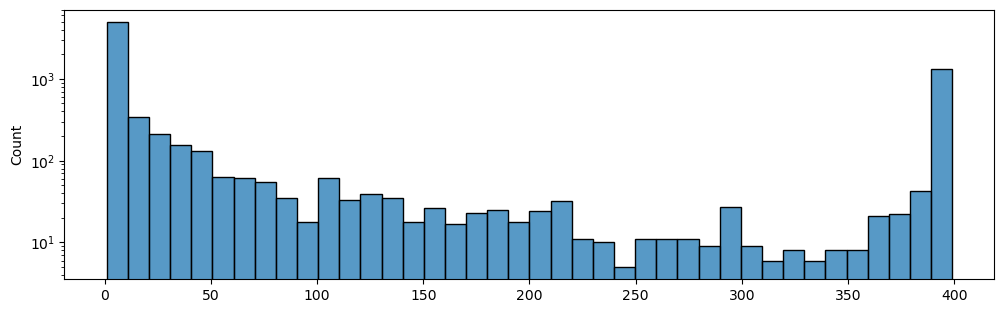

In [23]:
df_gene_freq = df_genes_final.sum(axis=1)

figsize = (12, 3.5)
fig, ax = plt.subplots(figsize=figsize)

sns.histplot(df_gene_freq, binwidth=10, ax=ax)
plt.yscale('log')
plt.show()

In [24]:
df_genes_final.shape

(7907, 399)

In [25]:
fig.savefig('freq.pdf', transparent=True)

In [26]:
fig.savefig('freq.png')

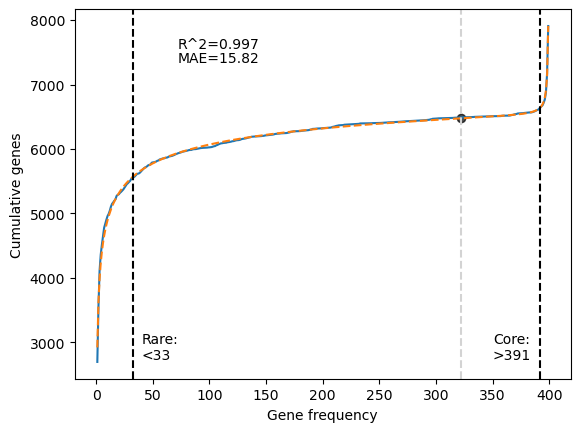

In [27]:
fig, ax = plt.subplots()

segments, popt, r_squared, mae, ax = find_pangenome_segments(df_genes_final, threshold=0.1, ax=ax)

In [28]:
fig.savefig('cdf.pdf', transparent=True)

In [29]:
fig.savefig('cdf.png')

In [30]:
df_freq = df_genes_final.sum(axis=1)

df_core = df_genes_final[df_freq > np.floor(segments[0])]
df_rare = df_genes_final[df_freq < np.ceil(segments[1])]

acc_gene_list = list(set(df_genes_final.index)
                     - set(df_core.index)
                     - set(df_rare.index)
                    )

df_acc = df_genes_final.loc[acc_gene_list].copy()

display(
    df_core.shape,
    df_acc.shape,
    df_rare.shape
)

(1282, 399)

(1071, 399)

(5554, 399)

In [31]:
core_genome_threshold = (int(segments[0])+1) / df_genes_final.shape[1]
rare_genome_threshold = (int(segments[1])+1) / df_genes_final.shape[1]
print(f'core genome threshold: {100 * core_genome_threshold} %')
print(f'rare genome threshold: {100 * rare_genome_threshold} %')

core genome threshold: 98.24561403508771 %
rare genome threshold: 8.270676691729323 %


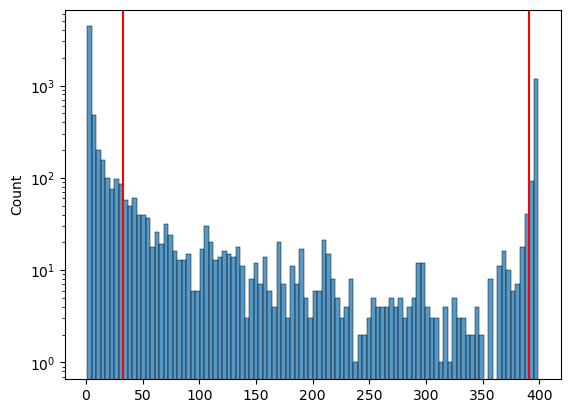

In [32]:
fig, ax = plt.subplots()
sns.histplot(df_gene_freq, binwidth=4, ax=ax)
plt.axvline(segments[0], color='red')
plt.axvline(segments[1], color='red')
plt.yscale('log')
plt.show()

In [33]:
# Make a dataframe for plotting CAR genome distribution per strain
df_car_dist = pd.DataFrame(index=df_genes_final.columns, columns=['core', 'acc','rare'])

# Fill in CAR
df_car_dist['core'] = df_core.sum()
df_car_dist['acc'] = df_acc.sum()
df_car_dist['rare'] = df_rare.sum()
df_car_dist['sum'] = df_car_dist.sum(axis=1)

df_car_dist.sort_values(by='sum', ascending=True)

,core,acc,rare,sum
1314.1005,1282,243,27,1552
1314.196,1280,256,29,1565
GCF_055361825.1,1279,256,33,1568
1437008.3,1281,266,24,1571
GCF_055361865.1,1282,259,32,1573
...,...,...,...,...
GCF_041072835.1,1282,453,151,1886
GCF_041430535.1,1277,474,139,1890
1314.2589,1280,472,152,1904
GCF_041072725.1,1282,469,183,1934


In [34]:
import plotly.graph_objects as go

# Sort the DataFrame by 'rare'
df_sorted = df_car_dist.sort_values(by='sum')

# Create x as a sequence representing the ordered samples
x = list(range(len(df_sorted)))

# Create a new figure
fig = go.Figure()

# Add scatter traces with stackgroup for stacking areas
fig.add_trace(go.Scatter(
    x=x,
    y=df_sorted['core'],
    name='core',
    stackgroup='one',
    mode='lines',
    line=dict(color='#8300c4'),
    fillcolor='#bea2cc'
))
fig.add_trace(go.Scatter(
    x=x,
    y=df_sorted['acc'],
    name='acc',
    stackgroup='one',
    mode='lines',
    line=dict(color='#ff7400'),
    fillcolor='#ffcf86'
))
fig.add_trace(go.Scatter(
    x=x,
    y=df_sorted['rare'],
    name='rare',
    stackgroup='one',
    mode='lines',
    line=dict(color='#93c47d'),
    fillcolor='#7bd7c3'
))

# Update layout to match original specifications
fig.update_layout(
    title='Filled Area Plot of Core, Acc, and Rare',
    xaxis_title='Samples ordered by Rare',
    yaxis_title='Values',
    yaxis=dict(range=[0, 2500]), # changed to 1000
    autosize=False,
    width=1200,
    height=550,
    margin=dict(l=50, r=50, b=100, t=100, pad=4),
    paper_bgcolor='white',
    plot_bgcolor='#e5e6eb'
)

# Hide x-axis labels
fig.update_xaxes(visible=False)

# Show the plot
fig.show()

In [35]:
print(f'median core genome: {int(df_core.sum().median())}, std: {int(df_core.sum().std())}')
print(f'median acc genome: {int(df_acc.sum().median())}, std: {int(df_acc.sum().std())}')
print(f'median rare genome: {int(df_rare.sum().median())}, std: {int(df_rare.sum().std())}')


median core genome: 1281, std: 8
median acc genome: 425, std: 70
median rare genome: 58, std: 46


In [36]:
fig.write_image('car_area_plot.png')

rare genome levels off fairly quickly


<Axes: ylabel='Proportion'>

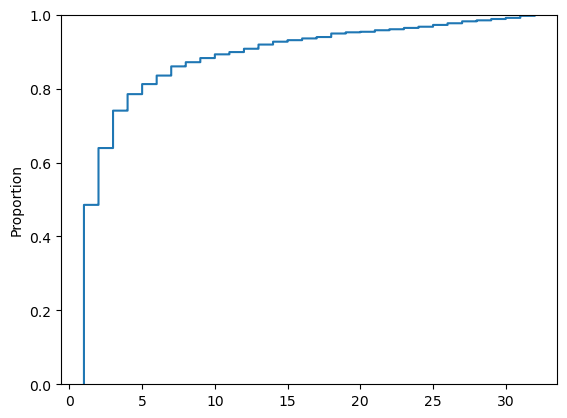

In [37]:
print('rare genome levels off fairly quickly')
sns.ecdfplot(data=df_rare.sum(axis=1))

# Save results

In [38]:
# Total
df_genes_final.to_pickle('/mnt/craig/pan_phylon/S_pyogenes/processed/CAR_genomes/df_genes_final.pickle')
df_core.to_pickle('/mnt/craig/pan_phylon/S_pyogenes/processed/CAR_genomes/df_core.pickle')
df_acc.to_pickle('/mnt/craig/pan_phylon/S_pyogenes/processed/CAR_genomes/df_acc.pickle')
df_rare.to_pickle('/mnt/craig/pan_phylon/S_pyogenes/processed/CAR_genomes/df_rare.pickle')

# PanTA Pangenome

The following is run in a linux terminal in a virtual conda enviroment with panTA installed

`panta main -o /mnt/craig/pan_phylon/S_pyogenes/processed/panTA-output -g /mnt/craig/pan_phylon/S_pyogenes/processed/gff3_files/*.gff3 -t 64 -i 0.8 -b diamond --AL 0.8`

In [39]:
df_genes_panta = pd.read_csv('/mnt/craig/pan_phylon/S_pyogenes/processed/panTA-output/gene_presence_absence.Rtab', sep='\t', index_col='Gene')
df_genes_panta

,1010840.4,1048264.3,1150773.3,1150773.4,1235829.3,1314.1001,1314.1002,1314.1003,1314.1004,1314.1005,...,GCF_055362005.1,GCF_055362025.1,GCF_055362045.1,GCF_055362065.1,GCF_055362085.1,GCF_055378755.1,GCF_900608505.1,GCF_900636425.1,GCF_900636485.1,GCF_900636725.1
Gene,,,,,,,,,,,,,,,,,,,,,
scl1,1,0,0,0,0,1,0,0,1,0,...,1,1,1,1,1,0,0,0,0,0
groups_1,1,0,0,0,0,0,0,0,1,0,...,0,0,0,0,0,0,0,1,1,0
groups_2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
groups_3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
groups_4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
groups_9695,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
groups_9696,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
groups_9697,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


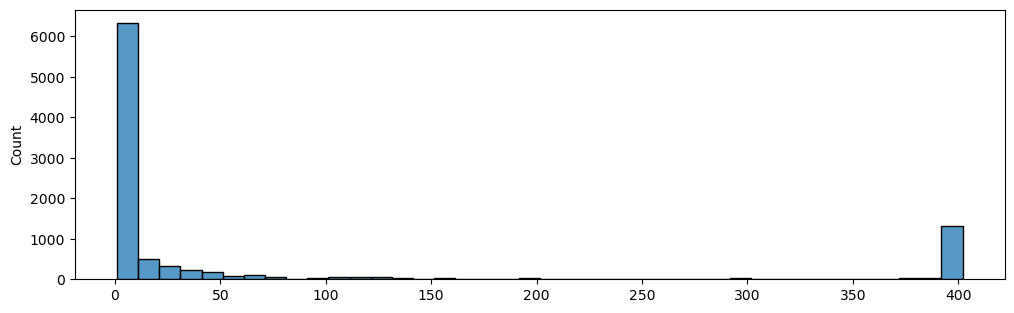

In [40]:
df_gene_freq_panta = df_genes_panta.sum(axis=1)

figsize = (12, 3.5)
fig, ax = plt.subplots(figsize=figsize)

sns.histplot(df_gene_freq_panta, binwidth=10, ax=ax)
#plt.yscale('log')
plt.show()

In [41]:
fig.savefig('freq_panta.pdf', transparent=True)

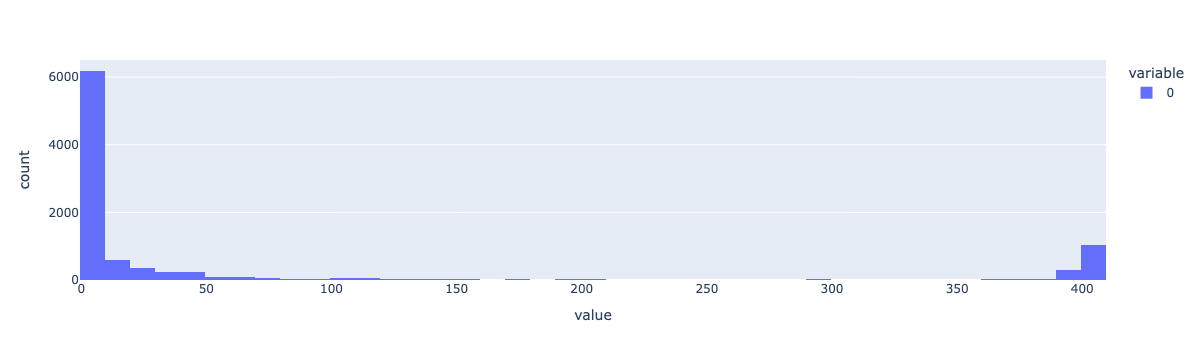

In [42]:
px.histogram(df_genes_panta.sum(axis=1)) # interactive plot

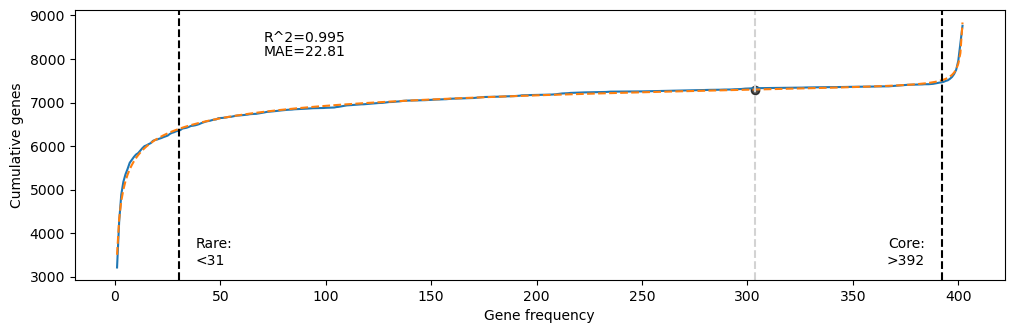

In [43]:
# original cd-hit constraints
figsize = (12, 3.5)
fig, ax = plt.subplots(figsize=figsize)

segments, popt, r_squared, mae, ax = find_pangenome_segments(df_genes, threshold=0.1, ax=ax)

In [44]:
#fig.savefig('cdf_panaroo.pdf', transparent=True)

In [45]:
df_freq_panta = df_genes_panta.sum(axis=1)

df_core_panta_cdhit = df_genes_panta[df_freq_panta > np.floor(segments[0])]
df_rare_panta_cdhit = df_genes_panta[df_freq_panta < np.ceil(segments[1])]

acc_gene_list_panta_cdhit = list(set(df_genes_panta.index)
                             - set(df_core_panta_cdhit.index)
                             - set(df_rare_panta_cdhit.index)
                          )

df_acc_panta_cdhit = df_genes_panta.loc[acc_gene_list_panta_cdhit].copy()

display(
    df_core_panta_cdhit.shape,
    df_acc_panta_cdhit.shape,
    df_rare_panta_cdhit.shape
)

(1305, 402)

(1243, 402)

(7152, 402)

In [46]:
# Make a dataframe for plotting CAR genome distribution per strain
df_car_dist_panta_cdhit = pd.DataFrame(index=df_genes_panta.columns, columns=['core', 'acc','rare'])

# Fill in CAR
df_car_dist_panta_cdhit['core'] = df_core_panta_cdhit.sum()
df_car_dist_panta_cdhit['acc'] = df_acc_panta_cdhit.sum()
df_car_dist_panta_cdhit['rare'] = df_rare_panta_cdhit.sum()
df_car_dist_panta_cdhit['sum'] = df_car_dist_panta_cdhit.sum(axis=1)

df_car_dist_panta_cdhit.sort_values(by='sum', ascending=True)

,core,acc,rare,sum
1314.1005,1303,209,34,1546
1314.196,1303,217,34,1554
GCF_055361825.1,1302,232,27,1561
1437008.3,1304,228,30,1562
1314.261,1304,229,32,1565
...,...,...,...,...
1314.2589,1302,447,189,1938
GCA_045345895.1,1139,388,417,1944
GCF_041071735.1,1304,444,221,1969
GCF_044361195.1,1305,466,201,1972


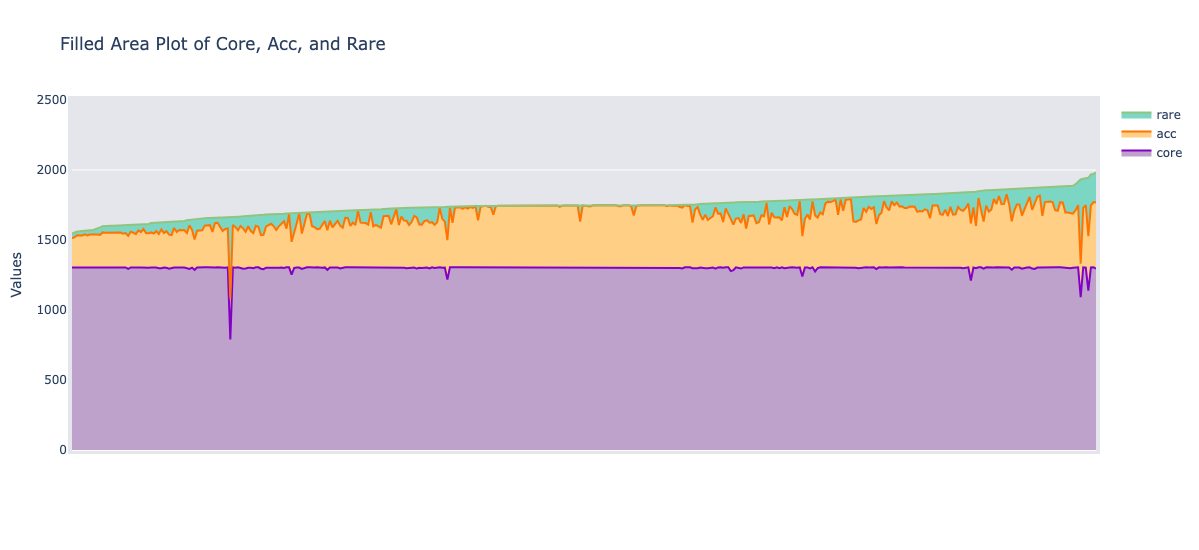

In [47]:
import plotly.graph_objects as go

# Sort the DataFrame by 'rare'
df_sorted = df_car_dist_panta_cdhit.sort_values(by='sum')

# Create x as a sequence representing the ordered samples
x = list(range(len(df_sorted)))

# Create a new figure
fig = go.Figure()

# Add scatter traces with stackgroup for stacking areas
fig.add_trace(go.Scatter(
    x=x,
    y=df_sorted['core'],
    name='core',
    stackgroup='one',
    mode='lines',
    line=dict(color='#8300c4'),
    fillcolor='#bea2cc'
))
fig.add_trace(go.Scatter(
    x=x,
    y=df_sorted['acc'],
    name='acc',
    stackgroup='one',
    mode='lines',
    line=dict(color='#ff7400'),
    fillcolor='#ffcf86'
))
fig.add_trace(go.Scatter(
    x=x,
    y=df_sorted['rare'],
    name='rare',
    stackgroup='one',
    mode='lines',
    line=dict(color='#93c47d'),
    fillcolor='#7bd7c3'
))

# Update layout to match original specifications
fig.update_layout(
    title='Filled Area Plot of Core, Acc, and Rare',
    xaxis_title='Samples ordered by Rare',
    yaxis_title='Values',
    yaxis=dict(range=[0, 2500]), # changed to 1000
    autosize=False,
    width=1200,
    height=550,
    margin=dict(l=50, r=50, b=100, t=100, pad=4),
    paper_bgcolor='white',
    plot_bgcolor='#e5e6eb'
)

# Hide x-axis labels
fig.update_xaxes(visible=False)

# Show the plot
fig.show()

In [48]:
print(f'core: {df_core_panta_cdhit.sum().median()}, std: {df_core_panta_cdhit.sum().std()}')
print(f'acc: {df_acc_panta_cdhit.sum().median()}, std: {df_acc_panta_cdhit.sum().std()}')
print(f'rare: {df_rare_panta_cdhit.sum().median()}, std: {df_rare_panta_cdhit.sum().std()}')

core: 1304.0, std: 29.941938848190997
acc: 382.0, std: 76.51480025868894
rare: 76.0, std: 70.35734880107408


In [49]:
sigma_mult = 4 # outlier multiplier

min_core_size_panta_cdhit = int(
    df_core_panta_cdhit.sum().median() - df_core_panta_cdhit.sum().std()*sigma_mult
)

min_acc_size_panta_cdhit = int(
    df_acc_panta_cdhit.sum().median() - df_acc_panta_cdhit.sum().std()*sigma_mult
)

max_rare_size_panta_cdhit = int(
    df_rare_panta_cdhit.sum().median() + df_rare_panta_cdhit.sum().std()*sigma_mult
)

max_pan_size_panta_cdhit = int(
    df_genes_panta.sum().median() + df_genes_panta.sum().std()*sigma_mult
)

cond1 = df_core_panta_cdhit.sum() < min_core_size_panta_cdhit
cond2 = df_acc_panta_cdhit.sum() < min_acc_size_panta_cdhit
cond3 = df_rare_panta_cdhit.sum() > max_rare_size_panta_cdhit
cond4 = df_genes_panta.sum() > max_pan_size_panta_cdhit

print('Either all of the below:')
print()
print(f'min core genome size < {min_core_size_panta_cdhit}')
print(f'min acc genome size < {min_acc_size_panta_cdhit}')
print(f'max # of genes per genome > {max_pan_size_panta_cdhit}')
print("-"*50)
print('OR:')
print()
print(f'max rare size > {max_rare_size_panta_cdhit}')
print("-"*50)
print(f'bad strains: {df_core_panta_cdhit.sum()[(cond1 & cond2 & cond4) | cond3].shape[0]}')

df_car_dist_panta_cdhit.loc[df_core_panta_cdhit.sum()[(cond1 & cond2 & cond4) | cond3].index].sort_values(by='core')


Either all of the below:

min core genome size < 1184
min acc genome size < 75
max # of genes per genome > 2067
--------------------------------------------------
OR:

max rare size > 357
--------------------------------------------------
bad strains: 3


,core,acc,rare,sum
1314.271,789,294,579,1662
GCA_000732385.1,1091,240,601,1932
GCA_045345895.1,1139,388,417,1944


In [50]:
# Remove outlier strains from P matrix and CAR submatrices
df_genes_panta_cdhit_final = df_genes_panta[df_core_panta_cdhit.sum()[~((cond1 & cond2 & cond4) | cond3)].index]

hasZeroPresence = df_genes_panta_cdhit_final.sum(axis=1) == 0
df_genes_panta_cdhit_final = df_genes_panta_cdhit_final[~hasZeroPresence]

df_genes_panta_cdhit_final

,1010840.4,1048264.3,1150773.3,1150773.4,1235829.3,1314.1001,1314.1002,1314.1003,1314.1004,1314.1005,...,GCF_055362005.1,GCF_055362025.1,GCF_055362045.1,GCF_055362065.1,GCF_055362085.1,GCF_055378755.1,GCF_900608505.1,GCF_900636425.1,GCF_900636485.1,GCF_900636725.1
Gene,,,,,,,,,,,,,,,,,,,,,
scl1,1,0,0,0,0,1,0,0,1,0,...,1,1,1,1,1,0,0,0,0,0
groups_1,1,0,0,0,0,0,0,0,1,0,...,0,0,0,0,0,0,0,1,1,0
groups_2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
groups_3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
groups_4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
groups_9695,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
groups_9696,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
groups_9697,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [51]:
# repeat for cd-hit-pangenome (for bounds calculations)
df_genes_cdhit_final = df_genes[df_core_panta_cdhit.sum()[~((cond1 & cond2 & cond4) | cond3)].index]

hasZeroPresence = df_genes_cdhit_final.sum(axis=1) == 0
df_genes_cdhit_final = df_genes_cdhit_final[~hasZeroPresence]

df_genes_cdhit_final

,1010840.4,1048264.3,1150773.3,1150773.4,1235829.3,1314.1001,1314.1002,1314.1003,1314.1004,1314.1005,...,GCF_055362005.1,GCF_055362025.1,GCF_055362045.1,GCF_055362065.1,GCF_055362085.1,GCF_055378755.1,GCF_900608505.1,GCF_900636425.1,GCF_900636485.1,GCF_900636725.1
Spyo_C0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Spyo_C1000,0,0,0,0,0,1,0,1,0,0,...,1,0,0,1,0,0,1,0,1,0
Spyo_C1001,0,0,0,0,0,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Spyo_C1002,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Spyo_C1003,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Spyo_C997,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Spyo_C998,1,1,1,1,1,1,1,1,1,1,...,1,1,1,1,1,1,1,1,1,1
Spyo_C999,0,0,1,1,1,1,0,1,0,0,...,0,0,0,1,0,1,1,0,1,1
Spyo_C99,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


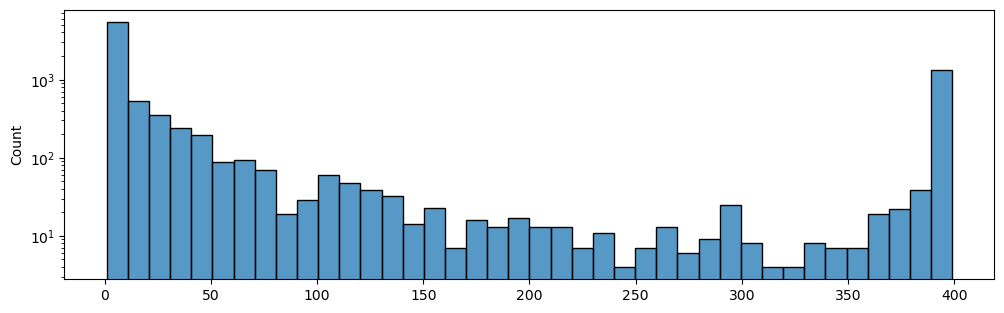

In [52]:
df_gene_freq_panta = df_genes_panta_cdhit_final.sum(axis=1)

figsize = (12, 3.5)
fig, ax = plt.subplots(figsize=figsize)
sns.histplot(df_gene_freq_panta, binwidth=10, ax=ax)
plt.yscale('log')

fig.savefig('df_genes_panta_cdhit_final_hist.pdf')

plt.show()

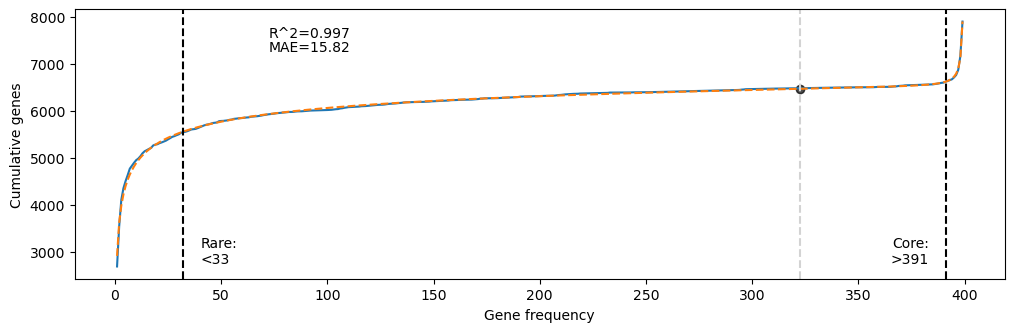

In [53]:
# We use the bounds but not the figure
figsize = (12, 3.5)
fig, ax = plt.subplots(figsize=figsize)

segments, popt, r_squared, mae, ax = find_pangenome_segments(df_genes_cdhit_final, threshold=0.1, ax=ax)

fig.savefig('df_genes_cdhit_final_gene_cdf.pdf')

In [54]:
segments, popt, r_squared, mae, ax

((np.float64(391.33852846588826), np.float64(32.23852846588826)),
 array([0.40765924, 0.60149278, 1.2257106 , 2.17520669, 2.88914914]),
 np.float64(0.9971676560838362),
 np.float64(15.822763035765139),
 <Axes: xlabel='Gene frequency', ylabel='Cumulative genes'>)

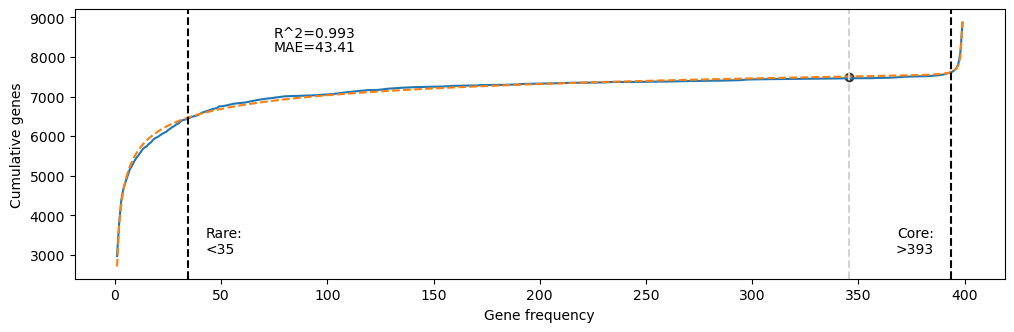

In [55]:
# We use the figure but not the bounds
figsize = (12, 3.5)
fig_pc, ax_pc = plt.subplots(figsize=figsize)

segments_pc, popt_pc, r_squared_pc, mae_pc, ax_pc = find_pangenome_segments(df_genes_panta_cdhit_final, threshold=0.1, ax=ax_pc)

fig.savefig('df_genes_panta_cdhit_final_gene_cdf.pdf')

In [56]:
df_freq_panta_cdhit = df_genes_panta_cdhit_final.sum(axis=1)

df_core_panta_cdhit = df_genes_panta_cdhit_final[df_freq_panta_cdhit > np.floor(segments[0])]
df_rare_panta_cdhit = df_genes_panta_cdhit_final[df_freq_panta_cdhit < np.ceil(segments[1])]

acc_gene_list_panta_cdhit = list(set(df_genes_panta_cdhit_final.index)
                                 - set(df_core_panta_cdhit.index)
                                 - set(df_rare_panta_cdhit.index)
                                )

df_acc_panta_cdhit = df_genes_panta_cdhit_final.loc[acc_gene_list_panta_cdhit].copy()

display(
    df_core_panta_cdhit.shape,
    df_acc_panta_cdhit.shape,
    df_rare_panta_cdhit.shape
)

(1292, 399)

(1167, 399)

(6405, 399)

In [57]:
core_genome_threshold = (int(segments[0])+1) / df_genes_panta_cdhit_final.shape[1]
rare_genome_threshold = (int(segments[1])+1) / df_genes_panta_cdhit_final.shape[1]
print(f'core genome threshold: {100 * core_genome_threshold} %')
print(f'rare genome threshold: {100 * rare_genome_threshold} %')

core genome threshold: 98.24561403508771 %
rare genome threshold: 8.270676691729323 %


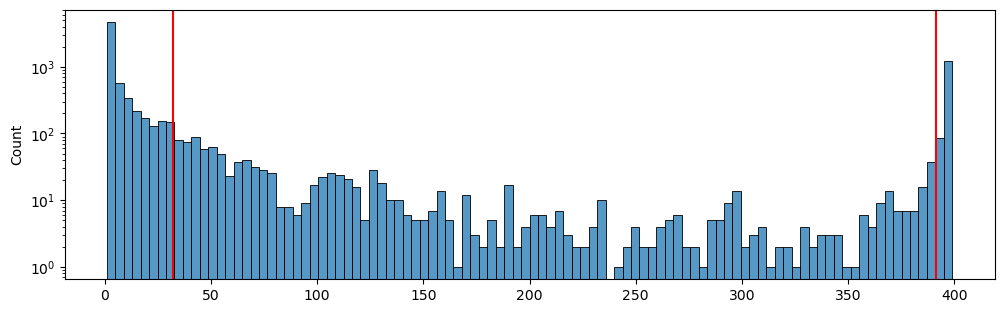

In [58]:
figsize = (12, 3.5)
fig, ax = plt.subplots(figsize=figsize)

sns.histplot(df_freq_panta_cdhit, binwidth=4, ax=ax)
plt.axvline(segments[0], color='red')
plt.axvline(segments[1], color='red')
plt.yscale('log')
plt.show()

In [59]:
# Make a dataframe for plotting CAR genome distribution per strain
df_car_dist_panta_cdhit = pd.DataFrame(index=df_genes_panta_cdhit_final.columns, columns=['core', 'acc','rare'])

# Fill in CAR
df_car_dist_panta_cdhit['core'] = df_core_panta_cdhit.sum()
df_car_dist_panta_cdhit['acc'] = df_acc_panta_cdhit.sum()
df_car_dist_panta_cdhit['rare'] = df_rare_panta_cdhit.sum()
df_car_dist_panta_cdhit['sum'] = df_car_dist_panta_cdhit.sum(axis=1)

df_car_dist_panta_cdhit.sort_values(by='sum', ascending=True)

,core,acc,rare,sum
1314.1005,1292,217,37,1546
1314.196,1290,229,35,1554
GCF_055361825.1,1289,243,29,1561
1437008.3,1291,241,30,1562
1314.261,1291,240,34,1565
...,...,...,...,...
GCF_041072725.1,1292,425,220,1937
1314.2589,1291,423,224,1938
GCF_041071735.1,1291,452,226,1969
GCF_044361195.1,1292,443,237,1972


In [60]:
df_car_dist_panta_cdhit.to_csv('df_car_dist_panta_cdhit.csv')

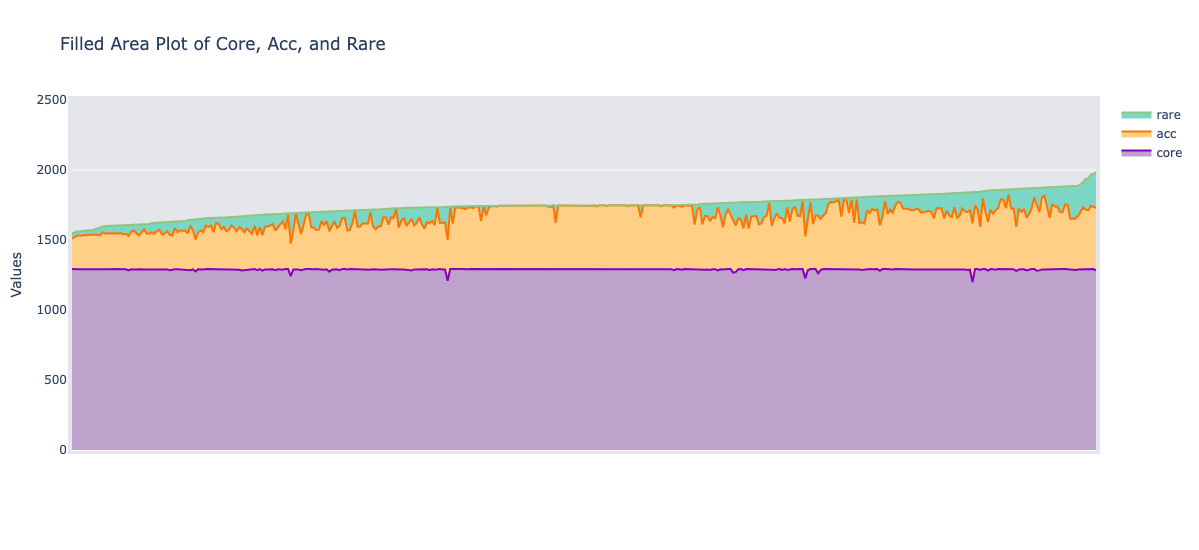

In [61]:
import plotly.graph_objects as go

# Sort the DataFrame by 'rare'
df_sorted = df_car_dist_panta_cdhit.sort_values(by='sum')

# Create x as a sequence representing the ordered samples
x = list(range(len(df_sorted)))

# Create a new figure
fig = go.Figure()

# Add scatter traces with stackgroup for stacking areas
fig.add_trace(go.Scatter(
    x=x,
    y=df_sorted['core'],
    name='core',
    stackgroup='one',
    mode='lines',
    line=dict(color='#8300c4'),
    fillcolor='#bea2cc'
))
fig.add_trace(go.Scatter(
    x=x,
    y=df_sorted['acc'],
    name='acc',
    stackgroup='one',
    mode='lines',
    line=dict(color='#ff7400'),
    fillcolor='#ffcf86'
))
fig.add_trace(go.Scatter(
    x=x,
    y=df_sorted['rare'],
    name='rare',
    stackgroup='one',
    mode='lines',
    line=dict(color='#93c47d'),
    fillcolor='#7bd7c3'
))

# Update layout to match original specifications
fig.update_layout(
    title='Filled Area Plot of Core, Acc, and Rare',
    xaxis_title='Samples ordered by Rare',
    yaxis_title='Values',
    yaxis=dict(range=[0, 2500]), # changed to 1000
    autosize=False,
    width=1200,
    height=550,
    margin=dict(l=50, r=50, b=100, t=100, pad=4),
    paper_bgcolor='white',
    plot_bgcolor='#e5e6eb'
)

# Hide x-axis labels
fig.update_xaxes(visible=False)

# Show the plot
fig.show()

In [62]:
df_car_dist_panta_cdhit.to_csv('df_car_dist_panta_cdhit.csv')

In [63]:
fig.write_image('CAR_genome_panta_cdhit.png')

In [64]:
# comparing median values to total values
display(
    df_car_dist_panta_cdhit['core'].median(),
    df_car_dist_panta_cdhit['acc'].median(),
    df_car_dist_panta_cdhit['rare'].median()
)

np.float64(1291.0)

np.float64(386.0)

np.float64(82.0)

In [65]:
# comparing median values to total values
display(
    df_car_dist_panta_cdhit['core'].std(),
    df_car_dist_panta_cdhit['acc'].std(),
    df_car_dist_panta_cdhit['rare'].std()
)

np.float64(8.01316909569394)

np.float64(76.29708256545527)

np.float64(63.64943529971115)

In [66]:
# comparing median values to total values
display(
    df_core_panta_cdhit.shape,
    df_acc_panta_cdhit.shape,
    df_rare_panta_cdhit.shape
)

(1292, 399)

(1167, 399)

(6405, 399)

In [67]:
# Total
df_genes_panta_cdhit_final.to_pickle('/mnt/craig/pan_phylon/S_pyogenes/processed/CAR_genomes/df_genes_panta_cdhit_final.pickle')
df_core_panta_cdhit.to_pickle('/mnt/craig/pan_phylon/S_pyogenes/processed/CAR_genomes/df_core_panta_cdhit.pickle')
df_acc_panta_cdhit.to_pickle('/mnt/craig/pan_phylon/S_pyogenes/processed/CAR_genomes/df_acc_panta_cdhit.pickle')
df_rare_panta_cdhit.to_pickle('/mnt/craig/pan_phylon/S_pyogenes/processed/CAR_genomes/df_rare_panta_cdhit.pickle')

In [68]:
df_genes_panta_cdhit_final.to_parquet('/mnt/craig/pan_phylon/S_pyogenes/processed/CAR_genomes/df_genes_panta_cdhit_final.parquet', compression='snappy')

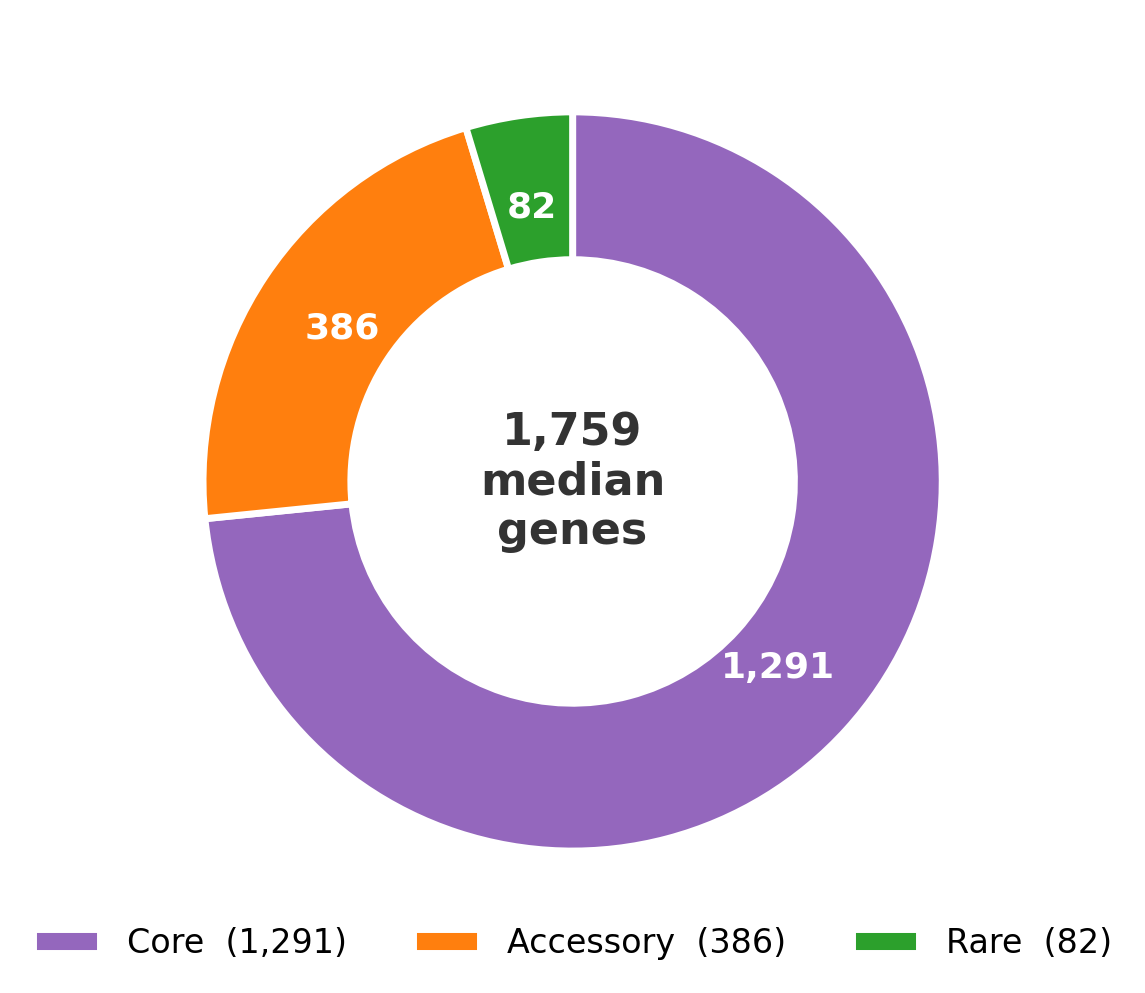

In [69]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib
#matplotlib.rcParams['font.family'] = 'sans-serif'

df = df_car_dist_panta_cdhit

med_core = df['core'].median()
med_acc = df['acc'].median()
med_rare = df['rare'].median()
total = med_core + med_acc + med_rare

labels = ['Core', 'Accessory', 'Rare']
values = [med_core, med_acc, med_rare]
# core=purple, acc=orange, rare=green
colors = ['#9467BD', '#FF7F0E', '#2CA02C']

fig, ax = plt.subplots(figsize=(6, 6), dpi=200)

wedges, texts, autotexts = ax.pie(
    values,
    labels=None,
    colors=colors,
    autopct=lambda pct: f'{int(round(pct/100.*total)):,}',
    pctdistance=0.75,
    startangle=90,
    counterclock=False,
    wedgeprops=dict(width=0.4, edgecolor='white', linewidth=2.5)
)

for t in autotexts:
    t.set_fontsize(13)
    t.set_fontweight('bold')
    t.set_color('white')

ax.text(0, 0, f'{int(total):,}\nmedian\ngenes', ha='center', va='center',
        fontsize=16, fontweight='bold', color='#333333')

legend = ax.legend(wedges, [f'{l}  ({v:,.0f})' for l, v in zip(labels, values)],
                   loc='lower center', bbox_to_anchor=(0.5, -0.05),
                   fontsize=12, frameon=False, ncol=3)

ax.set_aspect('equal')
# plt.tight_layout()
# plt.savefig('donut_car_median.png', dpi=300, bbox_inches='tight',
#             facecolor='white', transparent=False)
# plt.savefig('donut_car_median.svg', bbox_inches='tight',
#             facecolor='white', transparent=False)
plt.savefig('donut_car_median.pdf', transparent=True)
plt.show()

# Update and save metadata

In [70]:
car_metadata = metadata.set_index('genome_id').loc[df_car_dist_panta_cdhit.index]
car_metadata.index.name = 'genome_id'
car_metadata = car_metadata.reset_index()
car_metadata

/tmp/ipykernel_1165110/4040651928.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  car_metadata = car_metadata.reset_index()


,genome_id,source,genome_name,organism_name,taxon_id,strain,# ambiguous bases,# genomes,0,1,...,mash_cluster_initial,mash_cluster_filtered,iso_raw,host_cat,source_cat,country_merged,Num of emm-clusters,Predicted emm-type,Possible emm-like alleles,emm cluster
0,1010840.4,BV-BRC,Streptococcus pyogenes MGAS1882,Streptococcus pyogenes MGAS1882,1010840,MGAS1882,NaN,NaN,NaN,NaN,...,89,NaN,NaN,Not Specified,Not Specified,USA,2,emm_59.0,_emm_174.1*,E6
1,1048264.3,BV-BRC,Streptococcus pyogenes HKU QMH11M0907901,NaN,1048264,HKU QMH11M0907901,NaN,NaN,NaN,NaN,...,6,NaN,blood from scarlet fever outbreak,Human,Blood,China,1,emm_12.0,NaN,A-C4
2,1150773.3,BV-BRC,Streptococcus pyogenes JRS4,NaN,1150773,JRS4,NaN,NaN,NaN,NaN,...,7,8.0,NaN,Not Specified,Not Specified,NaN,1,emm_6.52,NaN,Single protein cluster clade Y
3,1150773.4,BV-BRC,Streptococcus pyogenes JRS4,NaN,1150773,JRS4,NaN,NaN,NaN,NaN,...,7,8.0,NaN,Not Specified,Not Specified,NaN,1,emm_6.52,NaN,Single protein cluster clade Y
4,1235829.3,BV-BRC,Streptococcus pyogenes A20,Streptococcus pyogenes A20,1235829,A20,NaN,NaN,NaN,NaN,...,2,2.0,necrotizing fasciitis patient,Human,Soft Tissue,Taiwan,1,emm_1.0,NaN,A-C3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
394,GCF_055378755.1,NCBI,NaN,Streptococcus pyogenes,1314,D58,0.0,30.0,2.0,674.0,...,16,6.0,NaN,Not Specified,Not Specified,USA,1,emm_3.0,NaN,A-C5
395,GCF_900608505.1,NCBI,NaN,Streptococcus pyogenes,1314,S119,0.0,240.0,1.0,523.0,...,2,2.0,blood culture,Human,Blood,France,1,emm_1.0,NaN,A-C3
396,GCF_900636425.1,NCBI,NaN,Streptococcus pyogenes,1314,NCTC12060,0.0,30.0,4.0,672.0,...,27,NaN,not available: to be reported later,Not Specified,Not Specified,United Kingdom,3,emm_80.0,_emm_156.1~*;_emm_138.1~*,D4
397,GCF_900636485.1,NCBI,NaN,Streptococcus pyogenes,1314,NCTC8232,0.0,30.0,2.0,673.0,...,12,NaN,not available: to be reported later,Not Specified,Not Specified,United Kingdom,1,emm_47.1,NaN,Single protein cluster clade Y


In [71]:
car_metadata.to_csv('/mnt/craig/pan_phylon/S_pyogenes/metadata/car_metadata.csv')